# Implementing PCA + SVM / Random Forrest / KNN on Indian Pines Dataset

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

In [2]:
import hvplot
import hvplot.pandas

pd.options.plotting.backend = 'hvplot'

In [3]:
# reading dataset
df = pd.read_csv("../dataset/pixels.csv")
df.head()

,band-1,band-2,band-3,band-4,band-5,band-6,band-7,band-8,band-9,band-10,...,band-192,band-193,band-194,band-195,band-196,band-197,band-198,band-199,band-200,class
0,3172,4142,4506,4279,4782,5048,5213,5106,5053,4750,...,1094,1090,1112,1090,1062,1069,1057,1020,1020,3
1,2580,4266,4502,4426,4853,5249,5352,5353,5347,5065,...,1108,1104,1117,1091,1079,1085,1064,1029,1020,3
2,3687,4266,4421,4498,5019,5293,5438,5427,5383,5132,...,1111,1114,1114,1100,1065,1092,1061,1030,1016,3
3,2749,4258,4603,4493,4958,5234,5417,5355,5349,5096,...,1122,1108,1109,1109,1071,1088,1060,1030,1006,3
4,2746,4018,4675,4417,4886,5117,5215,5096,5098,4834,...,1110,1107,1112,1094,1072,1087,1052,1034,1019,3


In [4]:
df['class'].value_counts()

class
0     10776
11     2455
2      1428
14     1265
10      972
3       830
6       730
12      593
5       483
8       478
15      386
4       237
13      205
16       93
1        46
7        28
9        20
Name: count, dtype: int64

In [5]:
# spliting features from pixel class label
# Remove pixels with class 0
df_filtered = df[df['class'] != 0]

X = df_filtered.iloc[:, :-1].values
y = df_filtered.iloc[:, -1].values

print(f"Original dataset shape: {df.shape}")
print(f"Filtered dataset shape (class 0 removed): {df_filtered.shape}")
print(f"X.shape: {X.shape}, y.shape: {y.shape}")

X.shape, y.shape

Original dataset shape: (21025, 201)
Filtered dataset shape (class 0 removed): (10249, 201)
X.shape: (10249, 200), y.shape: (10249,)


((10249, 200), (10249,))

### Training SVM without dimensiality reduction



In [7]:
X_train_full , X_test_full , y_train , y_test = train_test_split(X, y, random_state=11, test_size=0.2, stratify=y)

In [8]:
svm = SVC(kernel='rbf', degree = 10, gamma='scale', cache_size=1024*7)
svm.fit(X_train_full, y_train)

SVC(cache_size=7168, degree=10)

In [9]:
y_full_pred = svm.predict(X_test_full)

svm_accuracy = accuracy_score(y_test, y_full_pred)
print("SVM Accuracy with without dimensiality reduction: {:.2f}%".format(svm_accuracy * 100))

SVM Accuracy with without dimensiality reduction: 55.80%


In [10]:
report = classification_report(y_test, y_full_pred)
print(report)

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         9
           2       0.55      0.35      0.43       286
           3       0.00      0.00      0.00       166
           4       0.00      0.00      0.00        47
           5       0.72      0.19      0.30        97
           6       0.71      0.95      0.81       146
           7       0.00      0.00      0.00         5
           8       0.82      1.00      0.90        96
           9       0.00      0.00      0.00         4
          10       0.71      0.09      0.16       194
          11       0.43      0.95      0.59       491
          12       0.00      0.00      0.00       119
          13       0.84      0.90      0.87        41
          14       0.73      1.00      0.84       253
          15       1.00      0.04      0.07        77
          16       1.00      0.84      0.91        19

    accuracy                           0.56      2050
   macro avg       0.47   

C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} i

### Dimensiality Reduction with Principal Component Analysis (PCA)


- reducing number of components till we reach 0.95 cumulative variance

In [11]:
# Helper Function for Classification Map Visualization

def create_and_display_classification_map(y_train, y_test, predictions, indices_train, indices_test, df_filtered, title):
    """
    Create and display classification map for any model predictions.
    
    Parameters:
    - y_train: training labels
    - y_test: testing labels  
    - predictions: model predictions on test set
    - indices_train: indices of training samples
    - indices_test: indices of testing samples
    - df_filtered: filtered dataframe (without class 0)
    - title: title for the classification map
    """
    from tqdm import tqdm
    
    # Create mapping for filtered data
    clmap_filtered = [0]*len(y_train)
    
    for i in tqdm(range(len(indices_train)), desc="Mapping training data"):
        clmap_filtered[indices_train[i]] = y_train[indices_train[i]]
    
    for i in tqdm(range(len(indices_test)), desc="Mapping test predictions"):
        clmap_filtered[indices_test[i]] = predictions[i]
    
    # Map back to original grid (145x145), filling class 0 with 0
    original_indices = df_filtered.index.values
    clmap = [0]*(145*145)
    
    for orig_idx, filtered_idx in enumerate(original_indices):
        clmap[filtered_idx] = clmap_filtered[orig_idx]
    
    # Display the classification map
    plt.figure(figsize=(8, 6))
    plt.imshow(np.array(clmap).reshape((145, 145)), cmap='jet')
    plt.colorbar(label='Class')
    plt.axis('off')
    plt.title(title)
    plt.tight_layout()
    plt.show()
    
    return clmap


In [12]:
pca1 = PCA().fit(X)

# Explained variance (eigenvalues)
explained_var = pca1.explained_variance_

# Explained variance ratio (normalized eigenvalues)
explained_var_ratio = pca1.explained_variance_ratio_

# Cumulative explained variance ratio
cumulative_var = np.cumsum(explained_var_ratio)

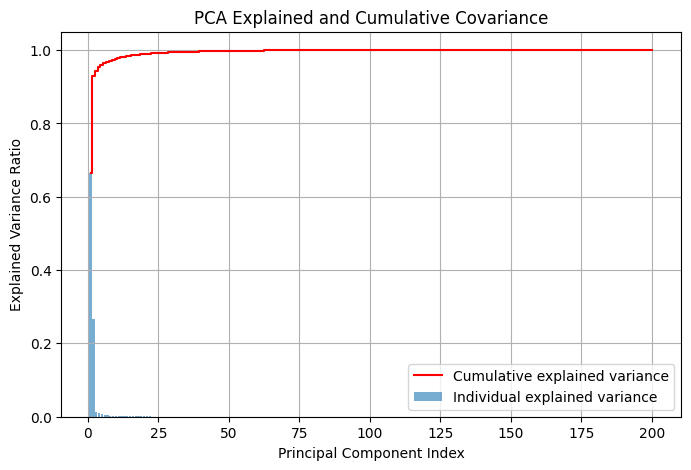

In [13]:
plt.figure(figsize=(8,5))

plt.bar(range(1, len(explained_var_ratio)+1), explained_var_ratio, 
        alpha=0.6, label='Individual explained variance')
plt.step(range(1, len(cumulative_var)+1), cumulative_var, 
         where='mid', color='red', label='Cumulative explained variance')

plt.xlabel('Principal Component Index')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA Explained and Cumulative Covariance')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [14]:
threshold = 0.99  # 99% of total variance
n_components_99 = np.argmax(cumulative_var >= threshold) + 1
print(f"Number of components explaining {threshold*100}% variance: {n_components_99}")


Number of components explaining 99.0% variance: 22


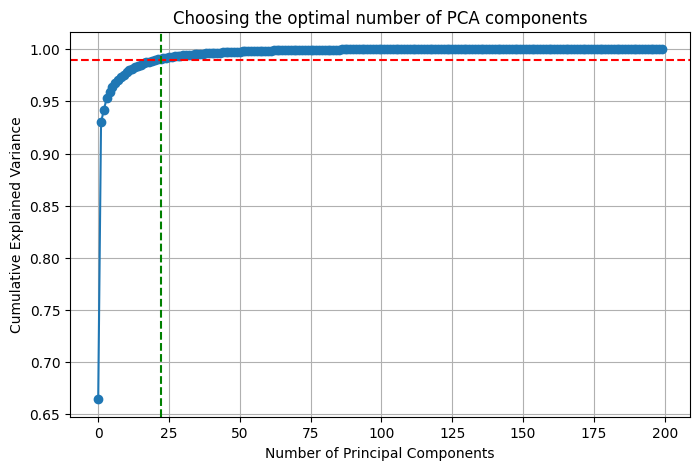

In [15]:
plt.figure(figsize=(8,5))
plt.plot(cumulative_var, marker='o', linestyle='-')
plt.axhline(y=threshold, color='r', linestyle='--')
plt.axvline(x=n_components_99, color='g', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Choosing the optimal number of PCA components')
plt.grid(True)
plt.show()

In [50]:
pca = PCA(n_components = 22)

principalComponents = pca.fit_transform(X)

ev=pca.explained_variance_ratio_

### Visualization of explained variance ratio

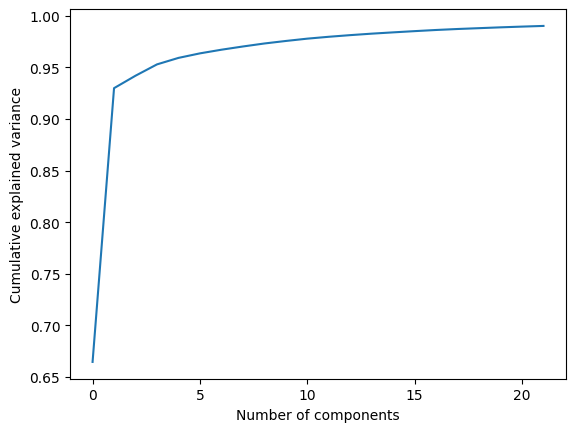

In [51]:
plt.plot(np.cumsum(ev))
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.show()

In [52]:
# Inetactive plot
df3 = pd.DataFrame(ev, columns=['Cumulative explained variance']).cumsum()
df3['Number of components'] = pd.Series(list(range(150)))
df3.plot(x='Number of components', y='Cumulative explained variance')

:Curve   [Number of components]   (Cumulative explained variance)

In [53]:
X_train, X_test, y_train, y_test, indices_train, indices_test = train_test_split(
    principalComponents,                
    y,                                  
    range(X.shape[0]),                 
    test_size=0.15,                     
    random_state=11,                    
    stratify=y                          
)

In [54]:
X_train.shape, X_test.shape

((8711, 22), (1538, 22))

### Training SVM

In [20]:
svm = SVC(kernel='rbf', gamma='scale', cache_size=1024*7)
svm.fit(X_train, y_train)

SVC(cache_size=7168)

In [21]:
y_pred = svm.predict(X_test)

In [22]:
svm_accuracy = accuracy_score(y_test, y_pred)
print("SVM Accuracy: {:.2f}%".format(svm_accuracy * 100))

SVM Accuracy: 74.25%


In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         7
           2       0.62      0.53      0.57       214
           3       0.79      0.47      0.59       125
           4       0.54      0.19      0.29        36
           5       0.90      0.92      0.91        72
           6       0.87      0.98      0.92       109
           7       1.00      0.75      0.86         4
           8       0.90      1.00      0.95        72
           9       0.00      0.00      0.00         3
          10       0.65      0.63      0.64       146
          11       0.64      0.88      0.74       368
          12       0.67      0.44      0.53        89
          13       0.91      1.00      0.95        31
          14       0.92      0.98      0.95       190
          15       0.91      0.53      0.67        58
          16       1.00      0.93      0.96        14

    accuracy                           0.74      1538
   macro avg       0.71   

C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} i

Mapping test predictions: 100%|██████████| 1538/1538 [00:00<00:00, 1534452.80it/s]



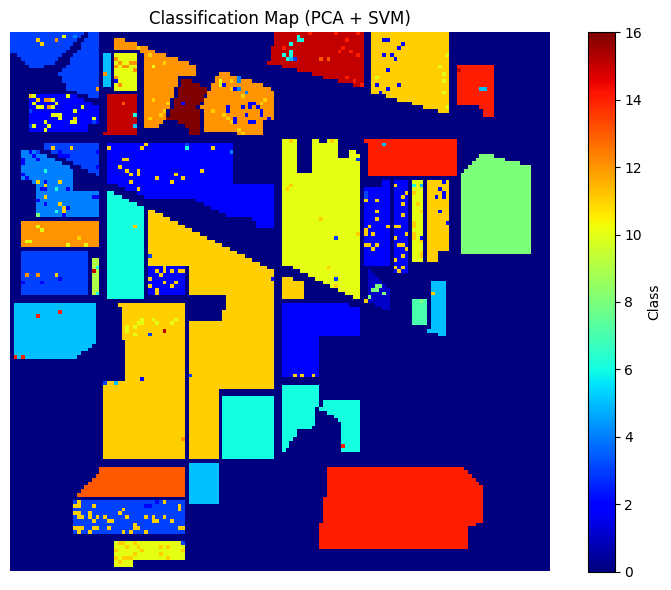

In [24]:
# Create and display SVM classification map
clmap = create_and_display_classification_map(
    y, y_test, y_pred, indices_train, indices_test, 
    df_filtered, 'Classification Map (PCA + SVM)'
)

### Training Random Forrest Classifier 

In [46]:
from sklearn.ensemble import RandomForestClassifier

# Create and train Random Forest
rf_classifier = RandomForestClassifier(n_estimators=213, random_state=42,min_samples_leaf=1)
rf_classifier.fit(X_train, y_train)

RandomForestClassifier(n_estimators=213, random_state=42)

In [47]:
# Make predictions
rf_predictions = rf_classifier.predict(X_test)

In [48]:
# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)
print("Random Forest Accuracy: {:.2f}%".format(rf_accuracy * 100))

Random Forest Accuracy: 82.44%


In [49]:
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_predictions))


Random Forest Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.71      0.83         7
           2       0.73      0.73      0.73       214
           3       0.85      0.68      0.76       125
           4       0.68      0.42      0.52        36
           5       0.92      0.93      0.92        72
           6       0.91      0.97      0.94       109
           7       1.00      0.75      0.86         4
           8       0.94      1.00      0.97        72
           9       1.00      0.33      0.50         3
          10       0.81      0.77      0.79       146
          11       0.76      0.86      0.81       368
          12       0.73      0.71      0.72        89
          13       0.94      0.97      0.95        31
          14       0.93      0.97      0.95       190
          15       0.88      0.64      0.74        58
          16       1.00      0.86      0.92        14

    accuracy                           0.8

Mapping test predictions: 100%|██████████| 1538/1538 [00:00<00:00, 1545111.27it/s]



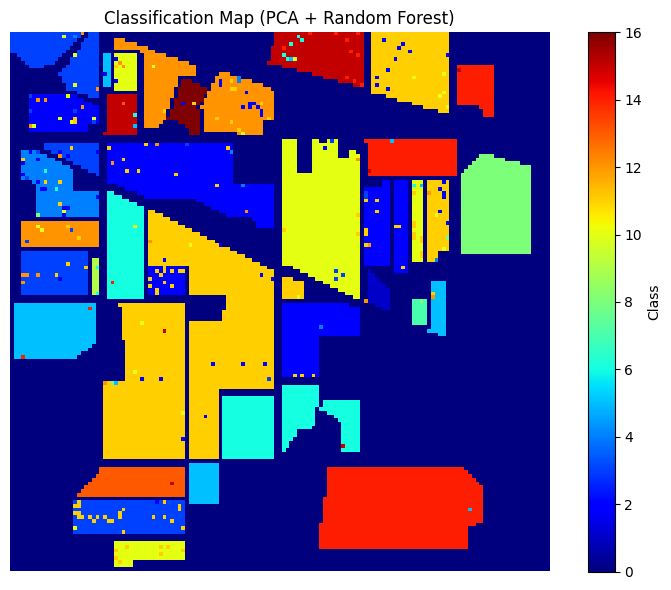

In [29]:
# Create and display Random Forest classification map
clmap_rf = create_and_display_classification_map(
    y, y_test, rf_predictions, indices_train, indices_test,
    df_filtered, 'Classification Map (PCA + Random Forest)'
)

### Training KNN Classifier

In [55]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [56]:
knn_predictions = knn.predict(X_test)

In [57]:
knn_accuracy = accuracy_score(y_test, knn_predictions)
print("KNN Accuracy: {:.2f}%".format(knn_accuracy * 100))


KNN Accuracy: 76.79%


In [58]:
print("\nKNN Classification Report:")
print(classification_report(y_test, knn_predictions))


KNN Classification Report:
              precision    recall  f1-score   support

           1       0.86      0.86      0.86         7
           2       0.60      0.69      0.64       214
           3       0.63      0.62      0.62       125
           4       0.53      0.50      0.51        36
           5       0.86      0.94      0.90        72
           6       0.88      0.98      0.93       109
           7       1.00      0.75      0.86         4
           8       0.96      0.99      0.97        72
           9       0.20      0.33      0.25         3
          10       0.71      0.68      0.70       146
          11       0.77      0.76      0.76       368
          12       0.72      0.52      0.60        89
          13       0.86      0.97      0.91        31
          14       0.95      0.96      0.96       190
          15       0.83      0.52      0.64        58
          16       1.00      0.93      0.96        14

    accuracy                           0.77      153

Mapping test predictions: 100%|██████████| 1538/1538 [00:00<00:00, 1541787.66it/s]



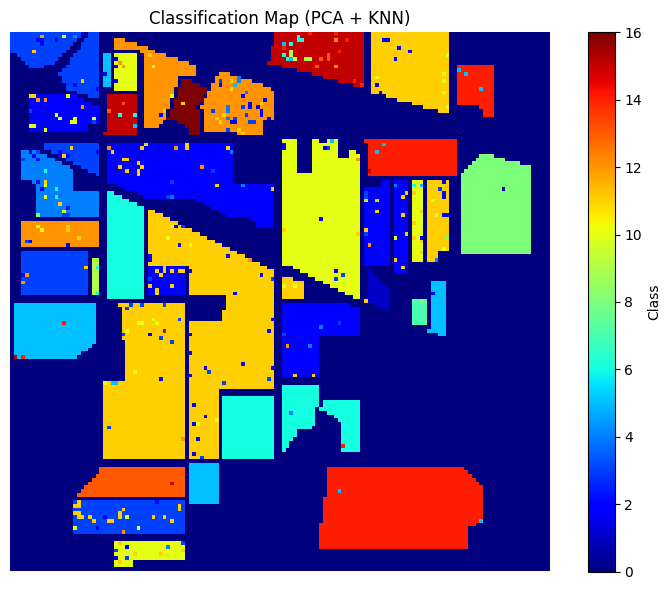

In [34]:
# Create and display KNN classification map
clmap_knn = create_and_display_classification_map(
    y, y_test, knn_predictions, indices_train, indices_test,
    df_filtered, 'Classification Map (PCA + KNN)'
)

### Training XGBoost Classifier 

In [59]:
import xgboost as xgb

# Remap class labels from 1-16 to 0-15
y_train_remapped = y_train - 1
y_test_remapped = y_test - 1

xgb_classifier = xgb.XGBClassifier(
    n_estimators=296,
    learning_rate=0.2,
    max_depth=4,
    subsample=0.6,
    colsample_bytree=0.8,
    random_state=42,
    num_class=16
)

xgb_classifier.fit(X_train, y_train_remapped)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.2, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=296,
              n_jobs=None, num_class=16, ...)

In [60]:
xgb_predictions = xgb_classifier.predict(X_test)
xgb_accuracy = accuracy_score(y_test_remapped, xgb_predictions)
print("XGBoost Accuracy: {:.2f}%".format(xgb_accuracy * 100))

XGBoost Accuracy: 84.92%


In [61]:
print("\nXGBoost Classification Report:")
print(classification_report(y_test_remapped, xgb_predictions))


XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86         7
           1       0.78      0.75      0.77       214
           2       0.84      0.70      0.76       125
           3       0.70      0.53      0.60        36
           4       0.96      0.94      0.95        72
           5       0.91      0.98      0.95       109
           6       1.00      0.75      0.86         4
           7       0.99      1.00      0.99        72
           8       0.50      0.33      0.40         3
           9       0.82      0.82      0.82       146
          10       0.79      0.87      0.83       368
          11       0.78      0.81      0.80        89
          12       0.97      1.00      0.98        31
          13       0.94      0.99      0.97       190
          14       0.90      0.64      0.75        58
          15       1.00      0.93      0.96        14

    accuracy                           0.85     

Mapping training data:   0%|          | 0/8711 [00:00<?, ?it/s]

Mapping training data: 100%|██████████| 8711/8711 [00:00<00:00, 527261.45it/s]

Mapping test predictions: 100%|██████████| 1538/1538 [00:00<00:00, 513030.03it/s]



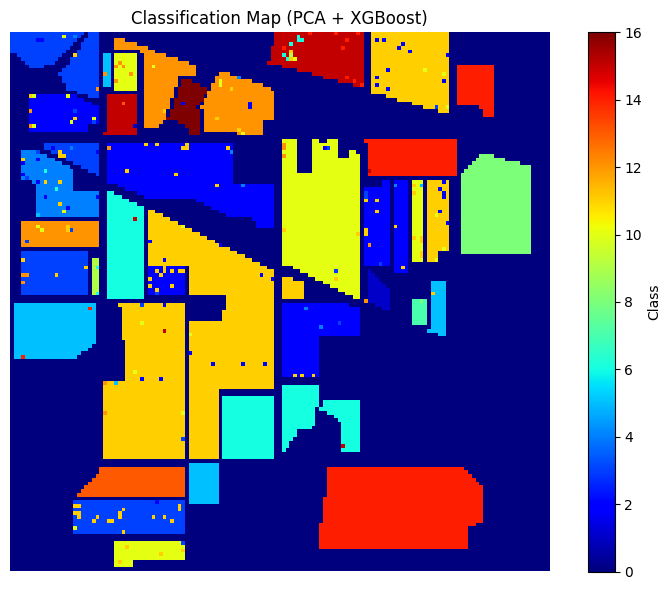

In [62]:
# Convert XGBoost predictions back from 0-15 to 1-16 for consistency
xgboost_pred_converted = xgb_predictions + 1

# Create and display XGBoost classification map
clmap_xgb = create_and_display_classification_map(
    y, y_test, xgboost_pred_converted, indices_train, indices_test,
    df_filtered, 'Classification Map (PCA + XGBoost)'
)

### Ground Truth Visualization and Model Comparison

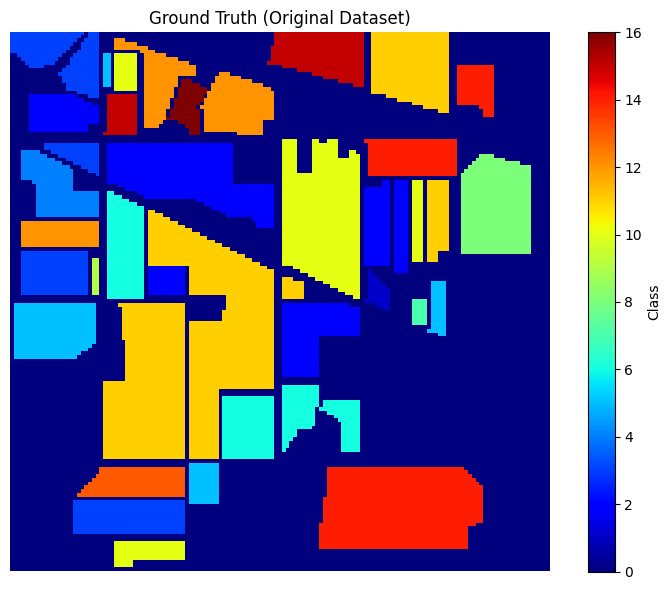

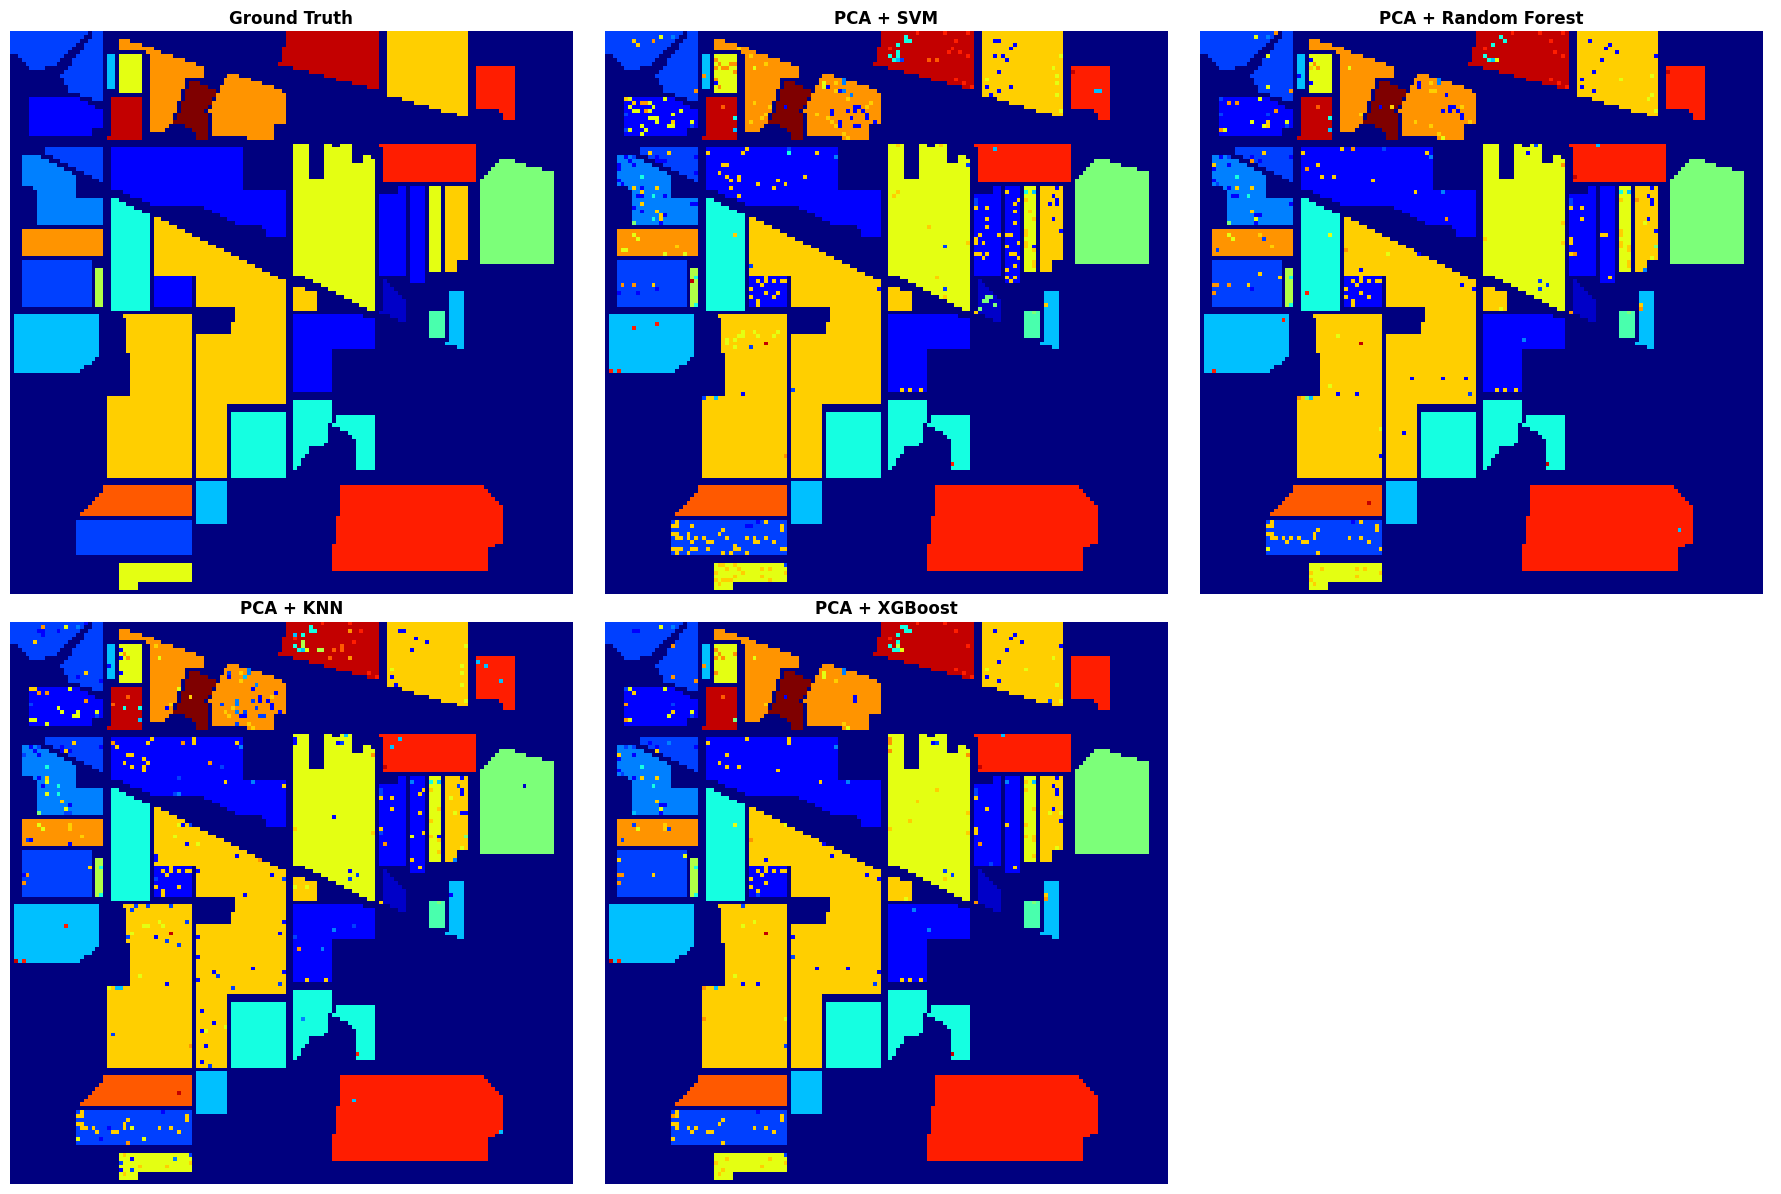

In [39]:


# Display Ground Truth
plt.figure(figsize=(8, 6))
plt.imshow(df.iloc[:, -1].values.reshape((145, 145)), cmap='jet')
plt.colorbar(label='Class')
plt.axis('off')
plt.title('Ground Truth (Original Dataset)')
plt.tight_layout()
plt.show()

# Create side-by-side comparison
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Ground Truth
axes[0, 0].imshow(df.iloc[:, -1].values.reshape((145, 145)), cmap='jet')
axes[0, 0].set_title('Ground Truth', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

# SVM
axes[0, 1].imshow(np.array(clmap).reshape((145, 145)), cmap='jet')
axes[0, 1].set_title('PCA + SVM', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

# Random Forest
axes[0, 2].imshow(np.array(clmap_rf).reshape((145, 145)), cmap='jet')
axes[0, 2].set_title('PCA + Random Forest', fontsize=12, fontweight='bold')
axes[0, 2].axis('off')

# KNN
axes[1, 0].imshow(np.array(clmap_knn).reshape((145, 145)), cmap='jet')
axes[1, 0].set_title('PCA + KNN', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

# XGBoost
axes[1, 1].imshow(np.array(clmap_xgb).reshape((145, 145)), cmap='jet')
axes[1, 1].set_title('PCA + XGBoost', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

# Hide the last subplot
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
import pandas as pd

pipe = Pipeline([
    ('scaler', StandardScaler()),       # optional
    ('pca', PCA()),                    
    ('svc', SVC())
])

param_grid = {
    'pca__n_components': [10, 15, 22, 30, 40],
    'svc__kernel': ['rbf'],
    'svc__C': [0.1, 1, 10],
    'svc__gamma': ['scale', 0.01, 0.001]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=11)
gs = GridSearchCV(pipe, param_grid, scoring='f1_macro', cv=cv, n_jobs=-1, verbose=2)
gs.fit(X_train, y_train)

# results
best_params = gs.best_params_
best_score = gs.best_score_
cv_results_df = pd.DataFrame(gs.cv_results_).sort_values('rank_test_score')
cv_results_df.to_csv('svm_pca_gridsearch_results.csv', index=False)

print("Best params:", best_params)
print("Best CV score (f1_macro):", best_score)

Fitting 5 folds for each of 45 candidates, totalling 225 fits


C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
90 fits failed out of a total of 225.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
45 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-

Best params: {'pca__n_components': 22, 'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Best CV score (f1_macro): 0.8388870452391813


In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

pipe = Pipeline([('pca', PCA()), ('rf', RandomForestClassifier(random_state=42))])

param_dist = {
    'pca__n_components': [10, 15, 22, 30, 40, 60],
    'rf__n_estimators': randint(50, 300),
    'rf__max_depth': randint(3, 20),
    'rf__min_samples_leaf': randint(1, 5)
}

rs = RandomizedSearchCV(pipe, param_distributions=param_dist,
                        n_iter=40, scoring='f1_macro', cv=cv, n_jobs=-1, random_state=42, verbose=2)
rs.fit(X_train, y_train)
pd.DataFrame(rs.cv_results_).to_csv('rf_pca_randomsearch.csv', index=False)
print(rs.best_params_, rs.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site

{'pca__n_components': 22, 'rf__max_depth': 16, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 213} 0.8060752388451558


In [42]:
from sklearn.neighbors import KNeighborsClassifier

pipe = Pipeline([('pca', PCA()), ('knn', KNeighborsClassifier())])
param_grid = {
    'pca__n_components': [10, 15, 22, 30],
    'knn__n_neighbors': [1,3,5,7,9],
    'knn__weights': ['uniform','distance']
}
gs_knn = GridSearchCV(pipe, param_grid, scoring='f1_macro', cv=cv, n_jobs=-1)
gs_knn.fit(X_train, y_train)
print(gs_knn.best_params_, gs_knn.best_score_)

C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
50 fits failed out of a total of 200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-

{'knn__n_neighbors': 3, 'knn__weights': 'distance', 'pca__n_components': 22} 0.7812198711888305


In [44]:
import xgboost as xgb
from sklearn.pipeline import Pipeline

pipe = Pipeline([('pca', PCA()), ('xgb', xgb.XGBClassifier(objective='multi:softmax', num_class=16, use_label_encoder=False, eval_metric='mlogloss'))])

param_dist = {
    'pca__n_components': [10, 15, 22, 30, 40],
    'xgb__n_estimators': randint(50, 300),
    'xgb__max_depth': randint(3, 8),
    'xgb__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'xgb__subsample': [0.6, 0.8, 1.0]
}

rs_xgb = RandomizedSearchCV(pipe, param_distributions=param_dist, n_iter=40, scoring='f1_macro', cv=cv, n_jobs=-1, random_state=42)
rs_xgb.fit(X_train, y_train_remapped)   # ensure y_train labels match XGBoost expected range
print(rs_xgb.best_params_, rs_xgb.best_score_)

C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
75 fits failed out of a total of 200.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
45 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ahmed\AppData\Roaming\Python\Python312\site-

{'pca__n_components': 22, 'xgb__learning_rate': 0.2, 'xgb__max_depth': 4, 'xgb__n_estimators': 296, 'xgb__subsample': 0.6} 0.8225818032792958


Mapping test predictions: 100%|██████████| 1538/1538 [00:00<00:00, 1541787.66it/s]



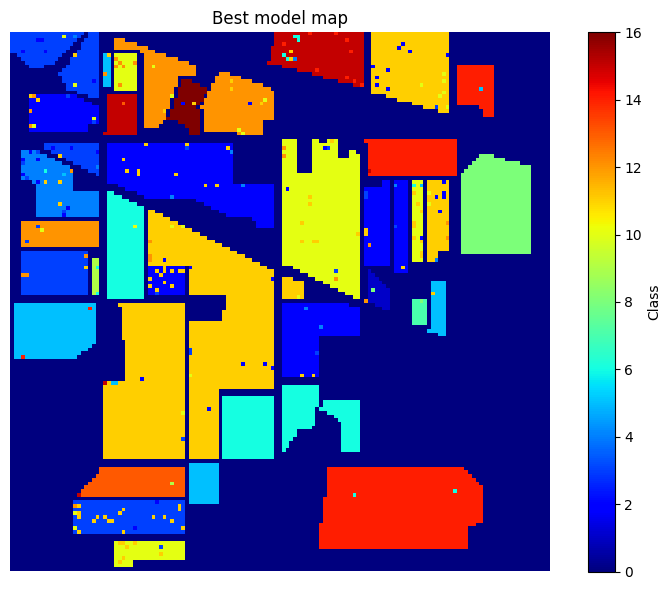

[np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 np.int64(3),
 0,
 np.int64(3),
 np.int64(3),
 np.int64(3),
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(14),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(14),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 np.int64(15),
 0,
 0,
 np.int64(11),
 np.int64(11),
 np.int64(11),
 np.int64(11),
 np.int64(11),
 np.int64(11),
 np.int64(11),
 np.int64(11)

In [45]:
# gs is best grid search object
best_clf = gs.best_estimator_
y_test_pred = best_clf.predict(X_test)
# visualize using the notebook helper create_and_display_classification_map
create_and_display_classification_map(y, y_test, y_test_pred, indices_train, indices_test, df_filtered, "Best model map")